In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 압축 풀기
import zipfile
import os
import pandas as pd

z_file = zipfile.ZipFile('./drive/MyDrive/1. BatteryAgingARC-FY08Q4.zip')
z_file.extractall('./DB/')
z_file.close()

os.remove('./DB/README.txt')

In [3]:
# 데이터 처리
import numpy as np
import matplotlib.pylab as plt
import scipy.io

X = {}
y = {}

path = './DB/'
f_names = ['B0005','B0006','B0007','B0018']

for f_name in f_names:
  mat_file = scipy.io.loadmat(path + f_name)
  is_charge = 0

  X_temp = []
  y_temp = []

  for i in range(len(mat_file[f_name][0][0][0][0])):
    if mat_file[f_name][0][0][0][0][i][0] == 'charge':
      if is_charge != 1:
        X_temp.append(mat_file[f_name][0][0][0][0][i][3][0][0])
        is_charge = 1
    elif mat_file[f_name][0][0][0][0][i][0] == 'discharge':
      if is_charge != 0:
        y_temp.append(mat_file[f_name][0][0][0][0][i][3][-1][-1][-1][0])
        is_charge = 0

  X[f_name] = X_temp
  y[f_name] = y_temp

In [4]:
data = 'B0005' # B0005, B0006, B0007, B0018

In [5]:
# 마지막 charge로 끝나는 데이터 제거

if data =='B0018':
  X = X[data][1:]

else:
  X = X[data][1:-1]

# 전체 용량
total_volume =  y[data][0]

# 방전 용량 첫값 제거
y = y[data][1:]

In [6]:
# uniform sampling, del outlier, normalization
def data_preprocessing(data,y,scaler=0,min_mA=0.01,num=30):

  # point time
  point_time = []
  for i in range(len(data)):
    temp_point_time = []
    for k in range(2,len(data[i][1][0])):
      if data[i][0][0][k]>=4.2:
        temp_point_time.append(data[i][5][0][k])
        break
    point_time.append(temp_point_time)

  for k in range(2,len(data[0][0][0])):
    if data[0][0][0][k]>=4.2:
      point_time1 = data[0][5][0][k-1]
      break

  CHV = []
  CHC = []
  TIME = []
  TEM = []
  Time = []

  for i in range(len(data)):
    temp_CHV = []
    temp_CHC = []
    temp_TIME = []
    temp_TEM = []
    temp_Time = []
    for k in range(0,len(data[i][1][0])):
        temp_TEM.append(data[i][2][0][k])
        temp_Time.append(data[i][5][0][k])
    TEM.append(temp_TEM)
    Time.append(temp_Time)
    for k in range(2,len(data[i][0][0])):
      if data[i][5][0][k]<point_time1:
        temp_CHV.append(data[i][0][0][k])
        temp_TIME.append(data[i][5][0][k])
      else:
        break

    for k in range(2,len(data[i][1][0])):
      if data[i][5][0][k]>=point_time1  and data[i][1][0][k]>=min_mA:
        temp_CHC.append(data[i][1][0][k])
#uniform sampling
    lines = np.linspace(2, len(temp_CHV)-1, num=num, dtype=np.uint64,endpoint=True)
    uniform_CHV = []
    uniform_TIME = []
    for line in lines:
      uniform_CHV.append(temp_CHV[line])
      uniform_TIME.append(temp_TIME[line])
    CHV.append(uniform_CHV)
    TIME.append(uniform_TIME)

    lines = np.linspace(2, len(temp_CHC)-1, num=num, dtype=np.uint64,endpoint=True)
    uniform_CHC = []
    for line in lines:
      uniform_CHC.append(temp_CHC[line])
    CHC.append(uniform_CHC)

  #normalization
  CHV_norm = scaler.fit_transform(np.asarray(CHV).reshape(-1,1))
  CHC_norm = scaler.fit_transform(np.asarray(CHC).reshape(-1,1))
  TIME_norm = scaler.fit_transform(np.asarray(TIME).reshape(-1,1))
  point_time = scaler.fit_transform(np.asarray(point_time).reshape(-1,1))
  #TEM = scaler.fit_transform(np.asarray(TEM).reshape(-1,1))
  #Time = scaler.fit_transform(np.asarray(Time).reshape(-1,1))
  ['충전 전압','충전 전류','온도','방전 용량']
  CHV = CHV_norm.reshape(-1,num,1)
  CHC = CHC_norm.reshape(-1,num,1)
  TIME = TIME_norm.reshape(-1,num,1)

  return np.concatenate((CHV,CHC,TIME),axis=2),np.asarray(y).reshape(-1,1), point_time, TEM, Time

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X, y, fx, TEM, Time = data_preprocessing(X,y,scaler)

In [8]:
#max_time 구하기
index = []
for i in range(len(Time)):
  for k in range(len(Time[i])):
    if Time[i][k] > 1000:
      index.append(Time[i].index(Time[i][k]))
      break

TEM_slice=[]
for i in range(len(Time)):
  TEM_slice.append(TEM[i][index[i]:])

Time_slice=[]
for i in range(len(Time)):
  Time_slice.append(Time[i][index[i]:])

max_index=[]
for i in range(len(TEM_slice)):
  max_index.append(TEM_slice[i].index(max(TEM_slice[i])))

max_Time = []
for i in range(len(Time_slice)):
  max_Time.append(Time_slice[i][max_index[i]])

In [9]:
max_time = np.asarray(max_Time).reshape(166,1)

In [10]:
np.shape(max_time)

(166, 1)

In [11]:
max_Time = scaler.fit_transform(np.asarray(max_Time).reshape(-1,1))

In [12]:
fx = np.asarray(fx).reshape(166,1)

In [13]:
np.shape(fx)

(166, 1)

In [14]:
np.shape(X)

(166, 30, 3)

In [15]:
fx = np.concatenate((fx,max_Time),axis=1)

In [16]:
np.shape(fx)

(166, 2)

In [17]:
def get_batch(X,fx,y,device,batch_size):
  idxs = np.arange(len(X))
  np.random.shuffle(idxs)
  rand_idxs = idxs[:batch_size]
  X_batch, fx_batch, y_batch = [],[],[]
  for idx in rand_idxs:
    X_batch.append(X[idx])
    fx_batch.append(fx[idx])
    y_batch.append(y[idx])
  #print(fx_batch)
  return torch.FloatTensor(X_batch).to(device),torch.FloatTensor(fx_batch).to(device),torch.FloatTensor(y_batch).to(device)

In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
import math

class LSTMCell(nn.Module) :
    def __init__(self, input_size, hidden_size, bias=True) :
        super(LSTMCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.bias = bias
        self.x2h = nn.Linear(input_size, 4*hidden_size, bias=bias)
        self.h2h = nn.Linear(hidden_size, 4*hidden_size, bias=bias)
        self.reset_parameters()

    def reset_parameters(self) :
        std = 1.0 / math.sqrt(self.hidden_size)
        for w in self.parameters() :
            w.data.uniform_(-std, std)

    def forward(self, x, hidden) :
        hx, cx = hidden
        x = x.view(-1, x.size(1))

        gates = self.x2h(x) + self.h2h(hx)
        # 현재 입력과 이전 은닉 상태에 대한 선형 변환 결과(출력)을 더함
        # self.x2h(x)와 self.h2h(hx)의 결과를 더하면 현재 입력과 이전 은닉 상태에 대한 선형 변환 결과가 결합된 게이트의 값이 계산됨
        # 이 게이트의 값은 LSTM 셀에서 중요한 역할을 하는 입력 게이트, 망각 게이트, 셀 게이트, 출력 게이트에 대한 정보를 포함
        gates = gates.squeeze()
        # 텐서의 크기가 1인 차원을 제거
        # 계산 상 편의를 위해 텐서의 크기를 조정
        ingate, forgetgate, cellgate, outgate = gates.chunk(4, 1)

        ingate = F.sigmoid(ingate) # 입력 게이트에 시그모이드 적용
        forgetgate = F.sigmoid(forgetgate) # 망각 게이트에 시그모이드 적용
        cellgate = F.tanh(cellgate) # 셀 게이트에 탄젠트 적용
        outgate = F.sigmoid(outgate) # 출력 게이트에 시그모이드 적용

        cy = torch.mul(cx, forgetgate) + torch.mul(ingate, cellgate)
        hy = torch.mul(outgate, F.tanh(cy))

        return (hy, cy)

drop out

In [19]:
class my_lstm(nn.Module) :
   def __init__(self,  hidden_dim, layer_dim, input_dim=3, output_dim=1, dropout_prob=0.085, bias=True) :
      # __init__: init 메서드, 컨스트럭터
      # init 메서드의 역할은 주로 클래스의 인스턴스 변수를 초기화하고, 모델의 구조를 설정하는 등의 작업을 수행
      # 1. 입력 차원, 은닉 상태 차원, 레이어 개수 등을 인자로 받아 해당 값을 인스턴스 변수에 저장

       super(my_lstm, self).__init__()
       # 부모 클래스의 __init__ 메서드를 호출
       self.hidden_dim = hidden_dim
       self.layer_dim = layer_dim
       self.dropout = nn.Dropout(dropout_prob)
       self.lstm = LSTMCell(input_dim, hidden_dim, layer_dim)
       self.fc = nn.Linear(hidden_dim+2, output_dim)
       # 2. LSTM 셀과 선형 레이어를 초기화하여 클래스의 인스턴스를 생성할 때 사용될 수 있도록 준비

       # 인스턴스: 클래스(템플릿)을 사용하여 실제 메모리에 생성된 객체
       # 인스턴스는 클래스에 정의된 속성이나 메서드에 접근할 수 있음
       # 인스턴스 변수: 인스턴스 변수는 해당 인스턴스에 속하는 변수로 인스턴스의 속성을 저장
       # 속성: 속성(Attribute)은 객체(object)가 가지는 데이터나 상태를 나타내는 변수
       # 속성 값을 인스턴스 변수에 저장

   def forward(self, x, fx) :
       if torch.cuda.is_available() :
        # GPU가 사용 가능한지 확인, 초기 은닉 상태와 초기 셀 상태를 GPU에 할당
           h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
           # Variable 클래스를 사용하여 데이터와 그래디언트를 저장할 수 있는 텐서를 생성
           # Pytorch 0.40 부터 텐서 자체가 그래디언트를 추적할 수 있게 됨
           # 3차원 텐서 생성
           # 첫 번째 차원: LSTM 레이어의 개수
           # 두 번째 차원: 한 번에 처리할 시퀀스(데이터)의 개수 = 입력 데이터의 첫 번째 차원
           # 세 번째 차원: LSTM 레이어의 은닉 상태(hidden state)의 차원
       else :
           h0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim))

       if torch.cuda.is_available() :
           c0 = Variable(torch.zeros(self.layer_dim, x.size(0), self.hidden_dim).cuda())
       else :
           c0 = Variable(torch.zeros(self.layer_dim, x.size(0), hidden_dim))

       outs = []
       cn =  c0[0,:,:]
       # c0의 첫 번째 차원 인덱스 0에 해당하는 2차원 텐서를 cn에 할당
       hn = h0[0,:,:]

       for seq in range(x.size(1)) :
           hn, cn = self.lstm(x[:, seq, :], (hn, cn))
           # 모든 배치에 대해 특정 시퀀스 인덱스의 모든 데이터를 추출
           outs.append(hn)

       out = outs[-1].squeeze()

       out = torch.cat([out, fx], dim = 1)
       out = self.fc(out)
       return out

In [20]:
def train(model,device,criterion,optimizer,X_train,fx_train,y_train,batch_size):
  model.train()
  # 모델을 학습 모드로 변경
  for i in range(int(len(X_train)/batch_size)+1): #학습 반복
    optimizer.zero_grad()
    # optimizer 변화도 초기화
    X_batch,fx_batch, y_batch = get_batch(X_train,fx_train,y_train,device,batch_size)
    # get_batch 함수를 사용하여 입력 데이터와 대상 데이터를 배치 단위로 가져옴
    pred = model(X_batch,fx_batch)
    # X_batch 예측값 계산
    loss = torch.sqrt(criterion(pred, y_batch))
    # 손실 계산
    loss.backward()
    # 역전파 수행
    optimizer.step()
    # 모델 파라미터 업데이트
    # 위 과정을 배치 개수 + 1 만큼 반복
  return loss.item()
  # 마지막 배치 오차 반환

In [21]:
def test(model,device,criterion,X,fx,y,total_volume):
  tensor = torch.FloatTensor(X).to(device)
  model.eval()
  with torch.no_grad():
    X,fx,y = torch.FloatTensor(X).to(device),torch.FloatTensor(fx).to(device),torch.FloatTensor(y).to(device)
    pred = model(X,fx)
  acc = torch.mean(abs(pred - y),dim=0).item()
  return acc

In [22]:
from sklearn.model_selection import train_test_split

def rand_sampling(X,fx,y,shuffle,train_ratio):
  indices = np.arange(len(X))
  X_train, X_test,fx_train,fx_test, y_train, y_test, train_idxs, test_idxs = train_test_split(X,fx,y,indices,train_size=train_ratio, shuffle = shuffle)
  return X_train, X_test,fx_train,fx_test, y_train, y_test, train_idxs, test_idxs

모델

In [23]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")  # device

learning_rate = 0.001
batch_size = 2
hidden_dim = 256
layer_dim = 3
#dropout_prob=0.085
# 네트워크 실험하면서 바꿔야할 부분
epoch = 100
train_ratio = 0.5
#sampling=30
# ====================== #

linear_X_train, linear_X_test,linear_fx_train,linear_fx_test, linear_y_train, linear_y_test, linear_train_idxs, linear_test_idxs = rand_sampling(X,fx,y,False,train_ratio=train_ratio)
print(linear_X_train.shape, linear_fx_train.shape)
criterion = nn.MSELoss()

linear_model = my_lstm(hidden_dim, layer_dim).to(device)

linear_optimizer = torch.optim.Adam(linear_model.parameters(), lr=learning_rate)

(83, 30, 3) (83, 2)


In [24]:
linear_losses = []
rand_losses = []

min_rand_test_loss = 100
min_linear_test_loss = 100
beat_linear_train_loss = 100

for i in range(1,epoch+1):
  # 1부터 100까지의 값을 순회하는 반복문
  # 100개의 에폭을 나타냄
  if i % 100 == 0:
    linear_optimizer.param_groups[0]['lr'] *= 0.5
    # 에폭이 100의 배수일 때 옵티마이저의 학습률을 0.5 배로 감소시킴
  linear_loss = train(linear_model,device,criterion,linear_optimizer,linear_X_train,linear_fx_train,linear_y_train,batch_size)
  # 모델 학습 손실 저장
  # 모델을 한 번의 에폭 동안 학습

  # 현재 에폭의 번호, 손실 값을 출력
  print(f'epoch : {i} / linear_loss : {round(linear_loss,5)}')
  linear_test_loss = test(linear_model,device,criterion,linear_X_test,linear_fx_test, linear_y_test,total_volume)
  linear_train_loss = test(linear_model,device,criterion,linear_X_train,linear_fx_train,linear_y_train,total_volume)

  if min_linear_test_loss > linear_test_loss:
    min_linear_test_loss = linear_test_loss
    torch.save(linear_model, './linear_model.pt')

  if beat_linear_train_loss > linear_train_loss:
    beat_linear_train_loss = linear_train_loss
    torch.save(linear_model, './best_train_linear_model.pt')


# plt.plot(rand_losses)
# plt.plot(linear_losses)

/tmp/ipykernel_639/2838313751.py:11: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  return torch.FloatTensor(X_batch).to(device),torch.FloatTensor(fx_batch).to(device),torch.FloatTensor(y_batch).to(device)


epoch : 1 / linear_loss : 0.04998
epoch : 2 / linear_loss : 0.01274
epoch : 3 / linear_loss : 0.01138
epoch : 4 / linear_loss : 0.01405
epoch : 5 / linear_loss : 0.05257
epoch : 6 / linear_loss : 0.03497
epoch : 7 / linear_loss : 0.01746
epoch : 8 / linear_loss : 0.02827
epoch : 9 / linear_loss : 0.01491
epoch : 10 / linear_loss : 0.02378
epoch : 11 / linear_loss : 0.05157
epoch : 12 / linear_loss : 0.04282
epoch : 13 / linear_loss : 0.04175
epoch : 14 / linear_loss : 0.00667
epoch : 15 / linear_loss : 0.02224
epoch : 16 / linear_loss : 0.01537
epoch : 17 / linear_loss : 0.03523
epoch : 18 / linear_loss : 0.03056
epoch : 19 / linear_loss : 0.00805
epoch : 20 / linear_loss : 0.00567
epoch : 21 / linear_loss : 0.01656
epoch : 22 / linear_loss : 0.0066
epoch : 23 / linear_loss : 0.01186
epoch : 24 / linear_loss : 0.02108
epoch : 25 / linear_loss : 0.00551
epoch : 26 / linear_loss : 0.0129
epoch : 27 / linear_loss : 0.00828
epoch : 28 / linear_loss : 0.00447
epoch : 29 / linear_loss : 0.01

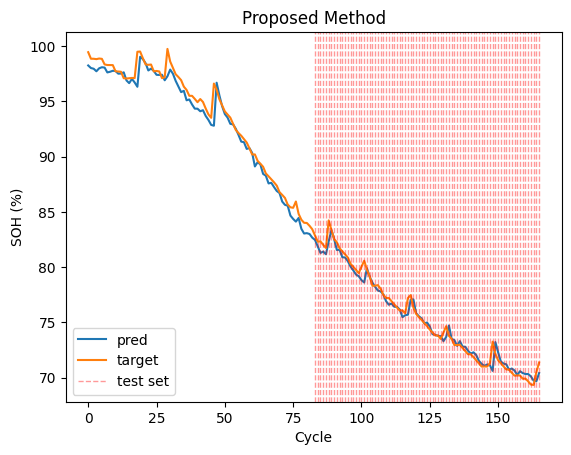

Error : [0.43837337] %


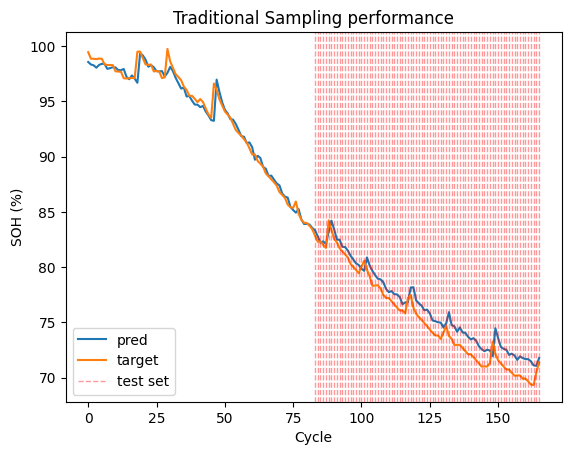

Error : [1.1475216] %


In [26]:
tensor = torch.FloatTensor(X).to(device)
tensor_fx = torch.FloatTensor(fx).to(device)

# weights_only=False 옵션을 포함하여 모델 로드
linear_model = torch.load('linear_model.pt', weights_only=False)
best_linear_model = torch.load('best_train_linear_model.pt', weights_only=False)

linear_pred = linear_model(tensor, tensor_fx)
best_linear_pred = best_linear_model(tensor, tensor_fx)

plt.plot(linear_pred.cpu().detach().numpy() / total_volume * 100)
plt.plot(y / total_volume * 100)
for i in linear_test_idxs:
    plt.axvline(i, c='r', linestyle='dashed', alpha=0.4, linewidth=1)
plt.ylabel('SOH (%)')
plt.xlabel('Cycle')
plt.title('Proposed Method')
plt.legend(['pred', 'target', 'test set'])
plt.show()
print(f'Error : {min_linear_test_loss / total_volume * 100} %')

plt.plot(best_linear_pred.cpu().detach().numpy() / total_volume * 100)
plt.plot(y / total_volume * 100)
for i in linear_test_idxs:
    plt.axvline(i, c='r', linestyle='dashed', alpha=0.4, linewidth=1)
plt.ylabel('SOH (%)')
plt.xlabel('Cycle')
plt.title('Traditional Sampling performance')
plt.legend(['pred', 'target', 'test set'])
plt.show()

linear_test_loss = test(best_linear_model, device, criterion, linear_X_test, linear_fx_test, linear_y_test, total_volume)
print(f'Error : {linear_test_loss / total_volume * 100} %')